# Genetic Drift

This notebook contains a series of simulations to highlight the mechanisms of genetic drift in the Wright-Fisher model.
This entire project was conducted in autonomy with no use of generative AI for code generation.

We consider a Wright-Fisher model with the following hypotheses:
* Discrete, non overlapping generations: time advances in discrete generations and the entire population is completely replaced by new individuals.
* Fixed population size
* Reproduction by duplication: an individual descends from one parent
* No selection: an individual picks a parent randomly from the previous generation
* No mutation: new alleles don't spawn spontaneously
* Geographical effects neglected

In this first model, we focus on one locus with two possible alleles. Thus, a population at a given generation is represented by an array of N binaries.

/!\ In this first section, as we focus on one locus, allele frequency designates the frequency of the observed locus being in state 1.

Goals of the simulations:
* Illustrate loss of diversity through time
* Follow the trajectory of a single allele and its probability of fixation

Vocabulary:
* Allele frequency of allele A: proportion of individuals carrying allele A in the population.
* Probability of fixation: probability that an allele eventually reaches a frequency of 1.


In [157]:
from random import randint
from math import floor
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress

In [18]:
class Population:
    """A population is an ensemble of individuals at a given generation.

    Attributes:
        size                The number of individuals in the population.
        generation          The number of the generation, starting from 0 and incrementing by 1 at each step.
        individuals         The list of individuals.
                            An individual is represented by a locus with a certain allele version (1 or 0).
        allele_frequency    The frequency of observed allele in the population.
    """
    def __init__(self, generation:int, size:int, individuals:list[int]):
        self.size = size
        self.generation = generation
        self.individuals = individuals
        self.allele_frequency = sum(self.individuals)/self.size

    def initialize_population(size:int, allele_frequency:float):
        allele_number = floor(allele_frequency*size)
        individuals = [1]*allele_number + [0]*(size - allele_number)
        return Population(generation=int(0), size=size, individuals=individuals)

    def next_generation_no_selection(self):
        new_generation_individuals = [0]*self.size
        for i in range(self.size):
            new_generation_individuals[i] = self.individuals[randint(0,self.size-1)]
        generation = self.generation + 1
        return Population(generation, self.size, new_generation_individuals)


In [151]:
def simulate_one_population(population_size,initial_allele_frequency,stop=None):

    if not stop:
        stop = 4*population_size

    previous_generation = Population.initialize_population(population_size,initial_allele_frequency)
    generation = 0
    allele_frequency = previous_generation.allele_frequency
    allele_frequencies=[allele_frequency]

    fixation = False

    while generation < stop - 1:
        next_generation = Population.next_generation_no_selection(previous_generation)
        generation +=1
        allele_frequency = next_generation.allele_frequency
        previous_generation = next_generation
        allele_frequencies.append(allele_frequency)

        if allele_frequency == 1.:
            fixation = True

    if fixation:
        stop_generation=allele_frequencies.index(1.0)
    else:
        if 0.0 in allele_frequencies:
            stop_generation=allele_frequencies.index(0.0)
        else:
            stop_generation=stop

    generations = list(range(stop))

    return generations, allele_frequencies, fixation, stop_generation

def simulate_n_populations(simulation_number,population_size,initial_allele_frequency,stop=None, show_plots=True):
    plt.clf()
    fixation_count = 0
    stop_generation_sum = 0

    for s in range(simulation_number):
         generations, allele_frequencies, fixation, stop_generation = simulate_one_population(population_size,initial_allele_frequency,stop)

         if simulation_number ==1:
            if fixation:
                print(f'Allele fixated in {stop_generation} generations.')
            else:
                print(f'Allele disappeared in {stop_generation} generations.')
            plt.plot(generations, allele_frequencies, alpha=0.6)
            plt.xlabel("Generation")
            plt.ylabel("Allele Frequency")
            plt.title("Evolution of single allele frequency over generations")
            plt.grid(alpha=0.3)
            plt.show()

         stop_generation_sum += stop_generation

         if fixation:
             fixation_count += 1

         if simulation_number>1 and show_plots:
             plt.plot(generations, allele_frequencies, alpha=0.6)

    avg_stop_generation = round(stop_generation_sum/simulation_number, 2)
    avg_stop_generation_in_pop_size = round(stop_generation_sum/simulation_number/population_size, 2)
    fixation_probability = round(fixation_count/simulation_number, 2)

    if simulation_number>1 and show_plots:
        print(f'Fixation probability: {fixation_probability}')
        print(f'Allele fixes or disappears in {avg_stop_generation} generations in average, or {avg_stop_generation_in_pop_size} time(s) population size.')


    if show_plots:
        plt.xlabel("Generation")
        plt.ylabel("Allele Frequency")
        plt.title("Evolution of single allele frequency over generations")
        plt.grid(alpha=0.3)
        plt.show()

    return fixation_probability, avg_stop_generation





To fix : don't count segregants in absorption generation count

### 1.1 Evolution of single allele frequency over generations - one simulation

Allele fixated in 158 generations.


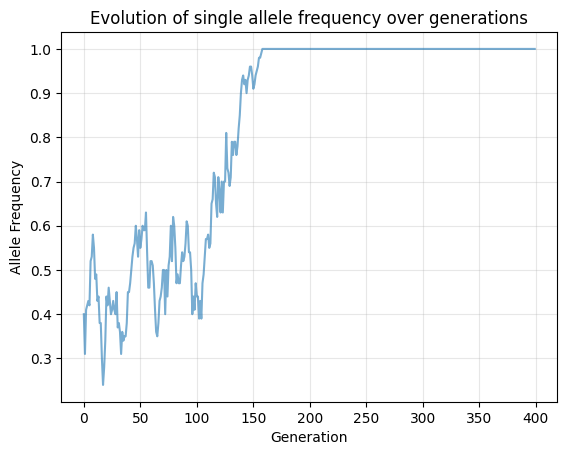

(1.0, 158.0)

In [150]:
#Try to run the cell with different population sizes and initial allele frequencies
SIMULATION_NUMBER = 1
POPULATION_SIZE = int(input("Population size= "))
INITIAL_ALLELE_FREQUENCY = float(input("Initial allele frequency (between 0 and 1)= "))

simulate_n_populations(SIMULATION_NUMBER,POPULATION_SIZE,INITIAL_ALLELE_FREQUENCY,show_plots=False)


### 1.2 Evolution of single allele frequency over generations - multiple simulations

Fixation probability: 0.36
Allele fixes or disappears in 134.66 generations in average, or 1.35 time(s) population size.


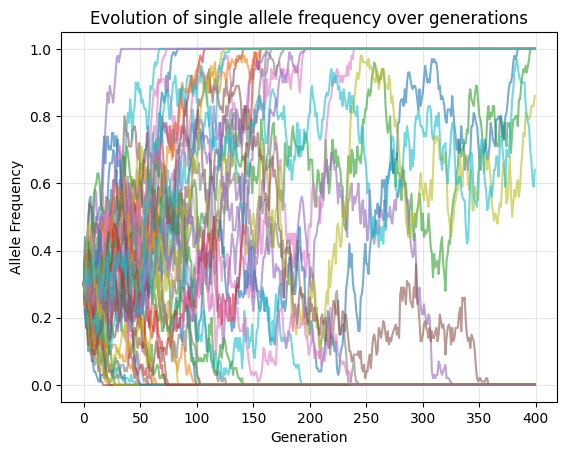

(0.36, 134.66)

In [153]:
SIMULATION_NUMBER = 50
POPULATION_SIZE = int(input("Population size= "))
INITIAL_ALLELE_FREQUENCY = float(input("Initial allele frequency = "))

simulate_n_populations(SIMULATION_NUMBER,POPULATION_SIZE,INITIAL_ALLELE_FREQUENCY)

Eventually, we observe that the allele always eventually reaches a frequency of 0 or 1 in the population: it either fixates or disappears, showing that diversity decreases in time.

### 1.3 Probability of fixation

For each allele frequency, 100 simulations are ran for a population of size 80


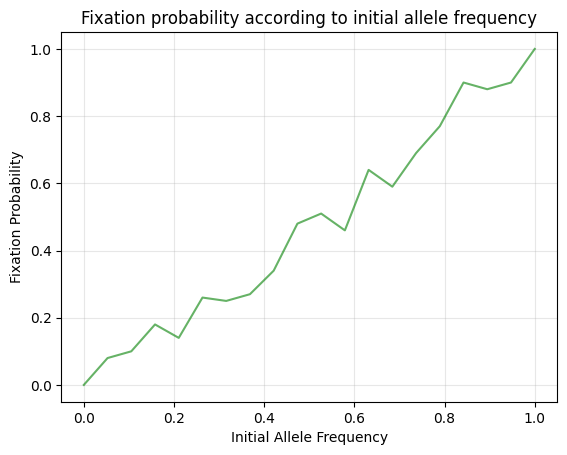

r = 0.9883892889448977


In [136]:
SIMULATION_NUMBER = 100
POPULATION_SIZE = int(input("Population size= "))

allele_frequencies = np.linspace(0, 1, 20)
fixation_probabilities=[]
for x in allele_frequencies:
    fixation_probabilities.append(simulate_n_populations(SIMULATION_NUMBER,POPULATION_SIZE,x, show_plots=False)[0])

print(f'At given allele frequency, {SIMULATION_NUMBER} simulations are ran for a population of size {POPULATION_SIZE}')
plt.clf()
plt.plot(allele_frequencies, fixation_probabilities, alpha=0.6, color='green')
plt.xlabel("Initial Allele Frequency")
plt.ylabel("Fixation Probability")
plt.title("Fixation probability according to initial allele frequency")
plt.grid(alpha=0.3)
plt.show()

r=np.corrcoef(allele_frequencies, fixation_probabilities)[0][1]
print(f'r = {r}')



### 1.4 Absorption time - initial allele frequency of 0.5

At given population size, 100 simulations are ran for a population with initial allele frequency of 0.5


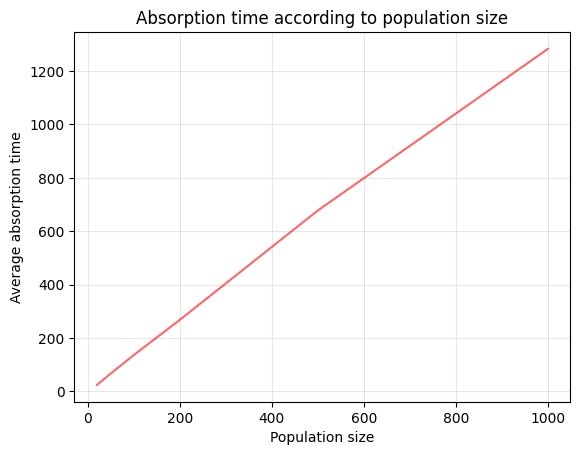

Pearson r = 0.9996028130953413
Slope = 1.2874011804189331


In [160]:
SIMULATION_NUMBER = 100
INITIAL_ALLELE_FREQUENCY = 0.5

population_sizes = [20, 50, 100, 200, 500, 1000]
avg_absorption_times=[]

for n in population_sizes:
    avg_absorption_times.append(simulate_n_populations(SIMULATION_NUMBER,n,INITIAL_ALLELE_FREQUENCY, show_plots=False)[1])

print(f'At given population size, {SIMULATION_NUMBER} simulations are ran for a population with initial allele frequency of {INITIAL_ALLELE_FREQUENCY}')
plt.clf()
plt.plot(population_sizes, avg_absorption_times, alpha=0.6, color='red')
plt.xlabel("Population size")
plt.ylabel("Average absorption time")
plt.title("Absorption time according to population size")
plt.grid(alpha=0.3)
plt.show()

r=np.corrcoef(population_sizes, avg_absorption_times)[0][1]
print(f'Pearson r = {r}')

reg = linregress(population_sizes, avg_absorption_times)
print(f'Slope = {reg.slope}')

Absorption time (average time before fixation/disappearance of allele) is proportional to population size.
An allele fixes or disappears in approximately 1.3N, which is coherent according to Kimura's diffusion equation:
$$\bar{t}(0.5) = -2 N \left[ 0.5 \ln(0.5) + (1 - 0.5) \ln(1 - 0.5) \right] = 2 N \ln(2) \approx 1,386 \, N$$

### 1.5 Absorption time - Small initial allele frequency

At given population size, 100 simulations are ran for a population with initial allele frequency of 0.01


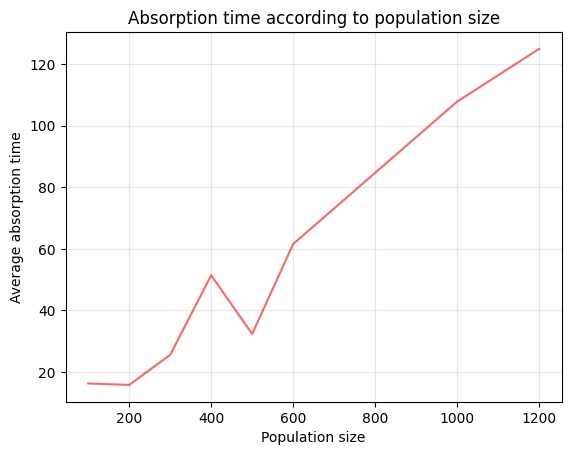

Pearson r = 0.9762657192678853
Proportionality coefficient = 0.10543634175691939


In [162]:
SIMULATION_NUMBER = 100
INITIAL_ALLELE_FREQUENCY = 0.01

population_sizes = [100, 200, 300, 400, 500, 600, 1000, 1200]
avg_absorption_times=[]

for n in population_sizes:
    avg_absorption_times.append(simulate_n_populations(SIMULATION_NUMBER,n,INITIAL_ALLELE_FREQUENCY, show_plots=False)[1])

print(f'At given population size, {SIMULATION_NUMBER} simulations are ran for a population with initial allele frequency of {INITIAL_ALLELE_FREQUENCY}')
plt.clf()
plt.plot(population_sizes, avg_absorption_times, alpha=0.6, color='red')
plt.xlabel("Population size")
plt.ylabel("Average absorption time")
plt.title("Absorption time according to population size")
plt.grid(alpha=0.3)
plt.show()

r=np.corrcoef(population_sizes, avg_absorption_times)[0][1]
print(f'Pearson r = {r}')

reg = linregress(population_sizes, avg_absorption_times)
print(f'Slope = {reg.slope}')

We get an absorption time proportional to population with a slope of approximately 1.1, which is coherent with the theory of Kimura's diffusion equation:
For $p_0 \ll 1$
:$$\bar{t}(p_0) \approx -2 N \left( p_0 \ln(p_0) + (1-p_0) \ln(1-p_0) \right)$$Pour $p_0 = 0.01$
$\bar{t} \approx -2 N \cdot (0.01 \ln(0.01) + 0.99 \ln(0.99)) \approx \mathbf{0.11 N}$